# GANisme — 03. Le générateur de peintures (DCGAN)

Ce notebook répond aux questions 6 à 8 de l'énoncé :

- **Q6** — architecture du GAN, fonctions de perte, entraînement sur nos données ;
- **Q7** — type de GAN choisi et hyperparamètres ;
- **Q8** — évaluation du modèle.

Tout le code du modèle, de l'entraînement et des métriques est **écrit dans ce notebook**. Le même code
existe aussi dans `src/ganisme/` (utilisé par l'application Streamlit et couvert par les tests) : la
section 6 vérifie que les deux versions sont identiques.

**Reprise et sauvegardes.** Après chaque époque, l'entraînement écrit un checkpoint complet
(`runs/<nom>/last.pt` : poids de G et D, états des optimiseurs, époque, historique, états aléatoires)
et une grille d'images générées à partir de vecteurs z fixes. Relancer le notebook reprend là où
l'entraînement s'est arrêté ; s'il est terminé, rien n'est recalculé.

## 0. Configuration

In [1]:
import json
import os
import random
import sys
import time
from dataclasses import asdict, dataclass
from pathlib import Path

import numpy as np
import torch
from IPython.display import Image, display
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
from torchvision.utils import save_image

ROOT = Path.cwd().resolve()
if not (ROOT / "src" / "ganisme").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

RUN = "dcgan_64"                                         # modele final
DATA = ROOT / "data" / "processed" / "dataset_64_v1.npz"  # jeu nettoye exporte par 02_dataset
REPORT = ROOT / "reports" / "training"
REPORT_V0 = ROOT / "reports" / "training_v0"              # baseline v0, pour comparaison

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| appareil :", device, "| threads CPU :", torch.get_num_threads())

torch 2.14.1+cpu | appareil : cpu | threads CPU : 16


## 1. Hyperparamètres (Q7)

**Type de GAN : DCGAN** (Radford et al., 2015), la référence pour des images 64×64. Il est assez léger
pour être entraîné sans GPU dédié et simple à diagnostiquer. StyleGAN produirait de meilleures images,
mais demanderait des jours de calcul sur GPU : il n'est pas adapté à une première version.

Les hyperparamètres sont ceux du papier DCGAN, un point de départ éprouvé :

| Paramètre | Valeur | Pourquoi |
| --- | --- | --- |
| Optimiseur | Adam | standard pour les GAN |
| Taux d'apprentissage | 0,0002 | valeur du papier, pour G et D |
| β1 | 0,5 | plus bas que la valeur par défaut (0,9) : moins d'inertie, entraînement plus stable |
| Taille de lot | 128 | valeur du papier |
| Dimension de z | 100 | taille du vecteur de bruit d'entrée |
| ngf / ndf | 64 | largeur de base de G et D |
| Augmentation | miroir horizontal | double la variété sans changer la nature d'une peinture |
| Époques | 100 | environ 4 700 itérations sur le jeu complet |

In [2]:
@dataclass
class Config:
    data: str = str(DATA)
    run_dir: str = str(ROOT / "runs" / RUN)
    epochs: int = 100
    batch_size: int = 128
    z_dim: int = 100
    ngf: int = 64
    ndf: int = 64
    lr: float = 2e-4
    beta1: float = 0.5
    seed: int = 42
    n_fixed: int = 64       # nombre de vecteurs z fixes pour suivre la progression
    hflip: bool = True


cfg = Config()
print(json.dumps({k: v for k, v in asdict(cfg).items() if k not in ("data", "run_dir")}, indent=1))

{
 "epochs": 100,
 "batch_size": 128,
 "z_dim": 100,
 "ngf": 64,
 "ndf": 64,
 "lr": 0.0002,
 "beta1": 0.5,
 "seed": 42,
 "n_fixed": 64,
 "hflip": true
}


## 2. Les données

Le jeu vient du notebook `02_dataset` : images 64×64 en `uint8`, réparties par œuvre entre
entraînement (90 %) et évaluation (10 %), sans quasi-doublons confirmés ni reproductions en noir et
blanc. Au chargement, les pixels passent de [0, 255] à [−1, 1], pour correspondre à la sortie `tanh` du
générateur.

In [3]:
def load_split(path, split):
    """Images uint8 (n, 64, 64, 3) d'un ensemble ('train' ou 'eval')."""
    with np.load(path) as data:
        return data["images"][data["split"] == split]


def to_tensor(images):
    """uint8 (n, h, w, 3) -> float (n, 3, h, w) dans [-1, 1]."""
    return torch.from_numpy(images).permute(0, 3, 1, 2).float().div(127.5).sub(1.0)


train_images, eval_images = load_split(cfg.data, "train"), load_split(cfg.data, "eval")
print(f"Entrainement : {train_images.shape} | evaluation : {eval_images.shape}")
assert len(train_images) > cfg.batch_size and len(eval_images) >= 100

Entrainement : (6105, 64, 64, 3) | evaluation : (657, 64, 64, 3)


## 3. Architecture (Q6)

**Générateur** : il part d'un vecteur de bruit z (100 × 1 × 1) et l'agrandit par **convolutions
transposées** de pas 2 : 4×4×512 → 8×8×256 → 16×16×128 → 32×32×64 → 64×64×3. Chaque étape est suivie
d'une BatchNorm et d'un ReLU ; la sortie passe par `tanh` (valeurs dans [−1, 1]).

**Discriminateur** : le chemin inverse, par **convolutions de pas 2** (pas de pooling, comme le
recommande le papier), BatchNorm (sauf sur la première couche) et LeakyReLU 0,2. Il renvoie un
**logit** ; la sigmoïde est appliquée dans la perte, ce qui est plus stable numériquement.

In [4]:
class Generator(nn.Module):
    """z (z_dim x 1 x 1) -> image 3 x 64 x 64 dans [-1, 1]."""

    def __init__(self, z_dim=100, ngf=64):
        super().__init__()

        def up(cin, cout):  # double la resolution
            return [nn.ConvTranspose2d(cin, cout, 4, 2, 1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(True)]

        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, ngf * 8, 4, 1, 0, bias=False), nn.BatchNorm2d(ngf * 8), nn.ReLU(True),  # 4x4
            *up(ngf * 8, ngf * 4),  # 8x8
            *up(ngf * 4, ngf * 2),  # 16x16
            *up(ngf * 2, ngf),      # 32x32
            nn.ConvTranspose2d(ngf, 3, 4, 2, 1, bias=False), nn.Tanh(),  # 64x64
        )

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    """Image 3 x 64 x 64 -> logit (probabilite d'etre vraie apres sigmoide)."""

    def __init__(self, ndf=64):
        super().__init__()

        def down(cin, cout, bn=True):  # divise la resolution par deux
            layers = [nn.Conv2d(cin, cout, 4, 2, 1, bias=False)]
            if bn:
                layers.append(nn.BatchNorm2d(cout))
            return layers + [nn.LeakyReLU(0.2, inplace=True)]

        self.net = nn.Sequential(
            *down(3, ndf, bn=False),   # 32x32
            *down(ndf, ndf * 2),       # 16x16
            *down(ndf * 2, ndf * 4),   # 8x8
            *down(ndf * 4, ndf * 8),   # 4x4
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),  # 1x1 : un logit par image
        )

    def forward(self, x):
        return self.net(x).view(-1)


def init_weights(module):
    """Initialisation du papier DCGAN : poids N(0 ; 0,02), BatchNorm N(1 ; 0,02)."""
    if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(module.weight, 0.0, 0.02)
    elif isinstance(module, nn.BatchNorm2d):
        nn.init.normal_(module.weight, 1.0, 0.02)
        nn.init.zeros_(module.bias)


G, D = Generator(cfg.z_dim, cfg.ngf), Discriminator(cfg.ndf)
count = lambda m: sum(p.numel() for p in m.parameters())
with torch.no_grad():
    fake = G(torch.randn(2, cfg.z_dim, 1, 1))
print(f"Generateur : {count(G):,} parametres | Discriminateur : {count(D):,} parametres")
print("Sortie de G :", tuple(fake.shape), "| sortie de D :", tuple(D(fake).shape))

Generateur : 3,576,704 parametres | Discriminateur : 2,765,568 parametres
Sortie de G : (2, 3, 64, 64) | sortie de D : (2,)


## 4. Fonctions de perte et boucle d'entraînement (Q6)

**Perte : entropie croisée binaire** (`BCEWithLogitsLoss`, qui inclut la sigmoïde).

- **Pas du discriminateur** : vraies images étiquetées 1, fausses étiquetées 0. Il minimise
  −[log D(x) + log(1 − D(G(z)))]. Les fausses images sont détachées (`detach`) : G n'est pas modifié.
- **Pas du générateur** : il minimise −log D(G(z)), c'est-à-dire qu'il cherche à faire répondre « vraie »
  au discriminateur. C'est la forme **non saturante** proposée par Goodfellow : elle garde des gradients
  utiles même quand D rejette facilement les faux. Le gradient traverse D, mais seul l'optimiseur de G
  avance.

**Contrôles pendant l'entraînement** : à chaque itération, on enregistre les pertes, la réponse moyenne
de D aux vraies et aux fausses images et la norme des gradients. L'entraînement s'arrête net si une valeur
n'est pas finie (NaN ou infini), plutôt que de continuer sur un modèle cassé.

**Sauvegardes** : écriture sûre (fichier temporaire relu, puis remplacement), pour ne jamais écraser un
checkpoint valide par un fichier corrompu.

In [5]:
def save_checkpoint(state, path):
    """Ecrit dans un fichier temporaire, le relit pour verifier, puis remplace l'ancien."""
    tmp = path.with_suffix(".tmp")
    torch.save(state, tmp)
    torch.load(tmp, map_location="cpu", weights_only=False)
    os.replace(tmp, path)


def grad_norm(model):
    norms = [p.grad.detach().norm() for p in model.parameters() if p.grad is not None]
    return float(torch.norm(torch.stack(norms))) if norms else 0.0


def train(cfg):
    run = Path(cfg.run_dir)
    (run / "samples").mkdir(parents=True, exist_ok=True)
    random.seed(cfg.seed); np.random.seed(cfg.seed); torch.manual_seed(cfg.seed)

    real = to_tensor(load_split(cfg.data, "train"))
    loader = DataLoader(TensorDataset(real), batch_size=cfg.batch_size, shuffle=True, drop_last=True)

    G, D = Generator(cfg.z_dim, cfg.ngf).to(device), Discriminator(cfg.ndf).to(device)
    G.apply(init_weights); D.apply(init_weights)
    opt_g = torch.optim.Adam(G.parameters(), lr=cfg.lr, betas=(cfg.beta1, 0.999))
    opt_d = torch.optim.Adam(D.parameters(), lr=cfg.lr, betas=(cfg.beta1, 0.999))
    bce = nn.BCEWithLogitsLoss()
    fixed_z = torch.randn(cfg.n_fixed, cfg.z_dim, 1, 1, generator=torch.Generator().manual_seed(cfg.seed)).to(device)

    # Reprise : si un checkpoint existe, on restaure tout (poids, optimiseurs, compteurs, hasard).
    history, start_epoch, it = [], 0, 0
    last = run / "last.pt"
    if last.exists():
        ckpt = torch.load(last, map_location=device, weights_only=False)
        G.load_state_dict(ckpt["G"]); D.load_state_dict(ckpt["D"])
        opt_g.load_state_dict(ckpt["opt_g"]); opt_d.load_state_dict(ckpt["opt_d"])
        history, start_epoch, it = ckpt["history"], ckpt["epoch"] + 1, ckpt["iteration"]
        torch.set_rng_state(ckpt["rng_torch"]); np.random.set_state(ckpt["rng_numpy"]); random.setstate(ckpt["rng_python"])
        print(f"Reprise a l'epoque {start_epoch} (iteration {it})")

    epochs_done = start_epoch
    for epoch in range(start_epoch, cfg.epochs):
        t0 = time.time()
        G.train(); D.train()
        for (x,) in loader:
            x = x.to(device)
            if cfg.hflip:  # miroir horizontal aleatoire, image par image
                flip = torch.rand(x.size(0), device=device) < 0.5
                x = torch.where(flip[:, None, None, None], x.flip(3), x)
            b = x.size(0)
            ones, zeros = torch.ones(b, device=device), torch.zeros(b, device=device)

            # Pas 1 : D apprend a separer vraies (1) et fausses (0) ; G est fige grace a detach().
            fake = G(torch.randn(b, cfg.z_dim, 1, 1, device=device))
            opt_d.zero_grad()
            out_real, out_fake = D(x), D(fake.detach())
            loss_d = bce(out_real, ones) + bce(out_fake, zeros)
            loss_d.backward()
            gn_d = grad_norm(D)
            opt_d.step()

            # Pas 2 : G apprend a faire dire "vraie" a D (perte non saturante -log D(G(z))).
            opt_g.zero_grad()
            loss_g = bce(D(fake), ones)
            loss_g.backward()
            gn_g = grad_norm(G)
            opt_g.step()

            values = [loss_d.item(), loss_g.item(), gn_d, gn_g]
            if not all(np.isfinite(values)):
                raise FloatingPointError(f"valeur non finie a l'iteration {it} : {values}")
            history.append({"iteration": it, "epoch": epoch, "loss_d": values[0], "loss_g": values[1],
                            "d_real": torch.sigmoid(out_real).mean().item(),
                            "d_fake": torch.sigmoid(out_fake).mean().item(), "grad_d": gn_d, "grad_g": gn_g})
            it += 1

        # Fin d'epoque : grille a partir des memes z, puis checkpoint complet.
        G.eval()
        with torch.no_grad():
            save_image(G(fixed_z), run / "samples" / f"epoch_{epoch:03d}.png", nrow=8, normalize=True, value_range=(-1, 1))
        save_checkpoint({"G": G.state_dict(), "D": D.state_dict(), "opt_g": opt_g.state_dict(), "opt_d": opt_d.state_dict(),
                         "epoch": epoch, "iteration": it, "history": history, "config": asdict(cfg),
                         "rng_torch": torch.get_rng_state(), "rng_numpy": np.random.get_state(),
                         "rng_python": random.getstate()}, last)
        epochs_done = epoch + 1
        recent = history[-len(loader):]
        print(f"epoque {epoch + 1}/{cfg.epochs} - {time.time() - t0:.0f}s - "
              f"loss_d {np.mean([h['loss_d'] for h in recent]):.3f} loss_g {np.mean([h['loss_g'] for h in recent]):.3f} "
              f"D(x) {np.mean([h['d_real'] for h in recent]):.2f} D(G(z)) {np.mean([h['d_fake'] for h in recent]):.2f}")
    return {"iterations": it, "epochs_done": epochs_done, "n_train": len(real), "history": history}

## 5. Entraînement

L'entraînement complet (100 époques sur ~6 100 images) prend environ 3 heures sur le processeur
(16 threads, pas de GPU NVIDIA). Il a été lancé en ligne de commande (`python -m ganisme.dcgan`, même
code), ce qui le protège d'une interruption du notebook. Ici, la fonction reprend depuis son checkpoint :
comme les 100 époques sont faites, elle ne recalcule rien et renvoie l'historique.

In [6]:
result = train(cfg)
history = result["history"]
last = [h for h in history if h["epoch"] == history[-1]["epoch"]]
print(f"{result['epochs_done']} epoques, {result['iterations']} iterations, {result['n_train']} images")
print(f"Derniere epoque : D(x) = {np.mean([h['d_real'] for h in last]):.2f}, "
      f"D(G(z)) = {np.mean([h['d_fake'] for h in last]):.2f}, "
      f"perte D = {np.mean([h['loss_d'] for h in last]):.2f}, perte G = {np.mean([h['loss_g'] for h in last]):.2f}")
assert result["epochs_done"] == cfg.epochs, "entrainement incomplet"

Reprise a l'epoque 100 (iteration 4700)
100 epoques, 4700 iterations, 6105 images
Derniere epoque : D(x) = 0.81, D(G(z)) = 0.18, perte D = 0.48, perte G = 3.54


## 6. Vérification : le code du notebook et celui de `src/ganisme` sont identiques

L'application et les tests utilisent `src/ganisme/dcgan.py` et `src/ganisme/evaluate.py`. On vérifie ici que
les deux versions donnent exactement le même modèle : mêmes couches et mêmes formes de poids, et mêmes
images produites quand on leur donne les mêmes poids et le même bruit.

In [7]:
from ganisme import dcgan as module

ckpt = torch.load(Path(cfg.run_dir) / "last.pt", map_location="cpu", weights_only=False)
for ours, theirs, key, args in ((Generator, module.Generator, "G", (cfg.z_dim, cfg.ngf)),
                                (Discriminator, module.Discriminator, "D", (cfg.ndf,))):
    a, b = ours(*args).eval(), theirs(*args).eval()
    a.load_state_dict(ckpt[key]); b.load_state_dict(ckpt[key])
    shapes_a = {k: tuple(v.shape) for k, v in a.state_dict().items()}
    shapes_b = {k: tuple(v.shape) for k, v in b.state_dict().items()}
    assert shapes_a == shapes_b, f"architectures differentes pour {key}"

G_nb, G_mod = Generator(cfg.z_dim, cfg.ngf).eval(), module.Generator(cfg.z_dim, cfg.ngf).eval()
G_nb.load_state_dict(ckpt["G"]); G_mod.load_state_dict(ckpt["G"])
z = torch.randn(8, cfg.z_dim, 1, 1, generator=torch.Generator().manual_seed(0))
with torch.no_grad():
    assert torch.equal(G_nb(z), G_mod(z))
print("Notebook et src/ganisme : architectures et images identiques.")

Notebook et src/ganisme : architectures et images identiques.


## 7. Évaluation (Q8)

Les métriques comparent des images générées au **jeu d'évaluation** (œuvres jamais vues à
l'entraînement), avec le même nombre d'images des deux côtés.

- **FID** (Fréchet Inception Distance) : on passe les images dans le réseau Inception v3 et on garde, pour
  chacune, un vecteur de 2 048 caractéristiques. On modélise chaque ensemble par une loi normale
  (moyenne μ, covariance Σ) et on mesure la distance entre les deux :
  ‖μ₁ − μ₂‖² + Tr(Σ₁ + Σ₂ − 2(Σ₁Σ₂)^½). Plus bas = mieux.
- **FID de référence** : le même calcul entre deux ensembles de **vraies** peintures de même taille. Le FID
  dépend beaucoup du nombre d'images : cette référence donne le meilleur score atteignable ici.
- **KID** (Kernel Inception Distance) : écart entre les deux ensembles mesuré avec un noyau polynomial,
  estimateur non biaisé, plus fiable sur de petits échantillons. Proche de 0 = ensembles indiscernables.
- **Plus proches voisins** : pour chaque image générée, la peinture d'entraînement la plus proche (cosinus
  entre caractéristiques Inception). Si elles sont identiques, le modèle recopie au lieu de créer.

Les caractéristiques viennent de l'Inception v3 de torchvision (poids ImageNet) : les valeurs se
comparent entre nos expériences, pas avec celles des articles (qui utilisent les poids TensorFlow).

In [8]:
from scipy import linalg


def fid(a, b):
    """Distance de Frechet entre deux nuages de caracteristiques (n, d)."""
    mu_a, mu_b = a.mean(0), b.mean(0)
    cov_a, cov_b = np.cov(a, rowvar=False), np.cov(b, rowvar=False)
    covmean = np.real(linalg.sqrtm(cov_a @ cov_b))
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(cov_a + cov_b - 2 * covmean))


def kid(a, b, subsets=50, size=500, seed=0):
    """KID : MMD non biaise avec le noyau k(x, y) = (x.y / d + 1)^3, moyenne sur des sous-ensembles."""
    rng = np.random.default_rng(seed)
    size = min(size, len(a) // 2, len(b) // 2)
    d = a.shape[1]
    values = []
    for _ in range(subsets):
        x, y = a[rng.choice(len(a), size, replace=False)], b[rng.choice(len(b), size, replace=False)]
        kxx, kyy, kxy = ((x @ x.T) / d + 1) ** 3, ((y @ y.T) / d + 1) ** 3, ((x @ y.T) / d + 1) ** 3
        n = size
        values.append((kxx.sum() - np.trace(kxx)) / (n * (n - 1)) + (kyy.sum() - np.trace(kyy)) / (n * (n - 1))
                      - 2 * kxy.mean())
    return float(np.mean(values)), float(np.std(values))


# Controle : memes valeurs que la version de src/ganisme, et comportement attendu.
from ganisme import evaluate as ev
rng = np.random.default_rng(1)
p, q = rng.normal(size=(400, 16)), rng.normal(loc=0.5, size=(400, 16))
assert np.isclose(fid(p, q), ev.fid(p, q)) and np.isclose(kid(p, q)[0], ev.kid(p, q)[0])
assert abs(fid(p, p)) < 1e-6 and fid(p, q) > 0
print("FID et KID : identiques a src/ganisme, nuls entre un ensemble et lui-meme.")

FID et KID : identiques a src/ganisme, nuls entre un ensemble et lui-meme.


Le calcul complet (extraction des caractéristiques Inception de ~6 800 images sur processeur, plus
proches voisins et figures) prend une dizaine de minutes : il est fait par `ganisme.evaluate` à la fin de
l'entraînement, avec les fonctions ci-dessus, et enregistré dans `reports/training/metrics.json`. On ne le
relance que si l'évaluation ne correspond pas au checkpoint courant.

In [9]:
metrics_path = REPORT / "metrics.json"
metrics = json.loads(metrics_path.read_text()) if metrics_path.exists() else {}
if not (metrics.get("dataset") == Path(cfg.data).name and metrics.get("epochs") == result["epochs_done"]):
    metrics = ev.evaluate(Path(cfg.run_dir), Path(cfg.data), REPORT / "figures")
    metrics_path.write_text(json.dumps(metrics, indent=2))
v0 = json.loads((REPORT_V0 / "metrics.json").read_text())

rows = [("FID (genere vs reel)", "fid"), ("FID de reference (reel vs reel)", "fid_real"),
        ("KID (genere vs reel)", "kid"), ("KID de reference", "kid_real"),
        ("Images d'entrainement", "n_train"), ("Images d'evaluation", "n_eval"),
        ("Epoques", "epochs"), ("Iterations", "iterations")]
print(f"{'':34}{'baseline v0':>14}{'modele final':>14}")
for label, key in rows:
    fmt = (lambda v: f"{v:.3f}") if key.startswith("kid") else (lambda v: f"{v:.1f}" if isinstance(v, float) else str(v))
    print(f"{label:34}{fmt(v0[key]):>14}{fmt(metrics[key]):>14}")
print("Attention : la v0 est evaluee ici sur SON jeu d'evaluation (296 images) : ces FID ne se comparent pas.")

# Comparaison equitable : memes 657 peintures d'evaluation pour les deux modeles (python -m ganisme.compare).
cmp_path = REPORT / "comparison.json"
if cmp_path.exists():
    cmp = json.loads(cmp_path.read_text())
    print(f"\nMeme jeu d'evaluation ({cmp['n_eval']} images) :")
    for name, label in (("reference (reel vs reel)", "Reference reel vs reel"), ("dcgan_64_v0", "Baseline v0"),
                        ("dcgan_64", "Modele final")):
        print(f"  {label:24} FID {cmp[name]['fid']:6.1f}   KID {cmp[name]['kid']:.3f}")

                                     baseline v0  modele final
FID (genere vs reel)                       352.6         210.8
FID de reference (reel vs reel)            100.5          62.4
KID (genere vs reel)                       0.309         0.150
KID de reference                          -0.000         0.000
Images d'entrainement                       2857          6105
Images d'evaluation                          296           657
Epoques                                       30           100
Iterations                                   660          4700
Attention : la v0 est evaluee ici sur SON jeu d'evaluation (296 images) : ces FID ne se comparent pas.

Meme jeu d'evaluation (657 images) :
  Reference reel vs reel   FID   62.4   KID 0.000
  Baseline v0              FID  335.4   KID 0.305
  Modele final             FID  210.8   KID 0.150


losses


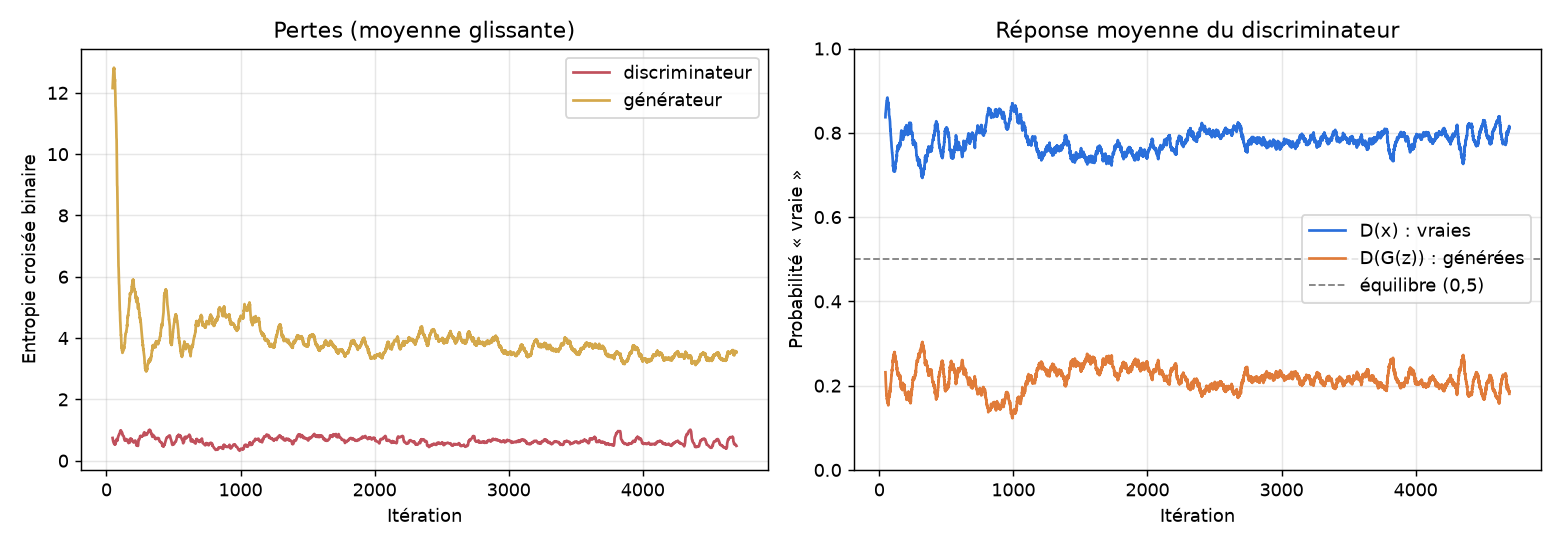

progression


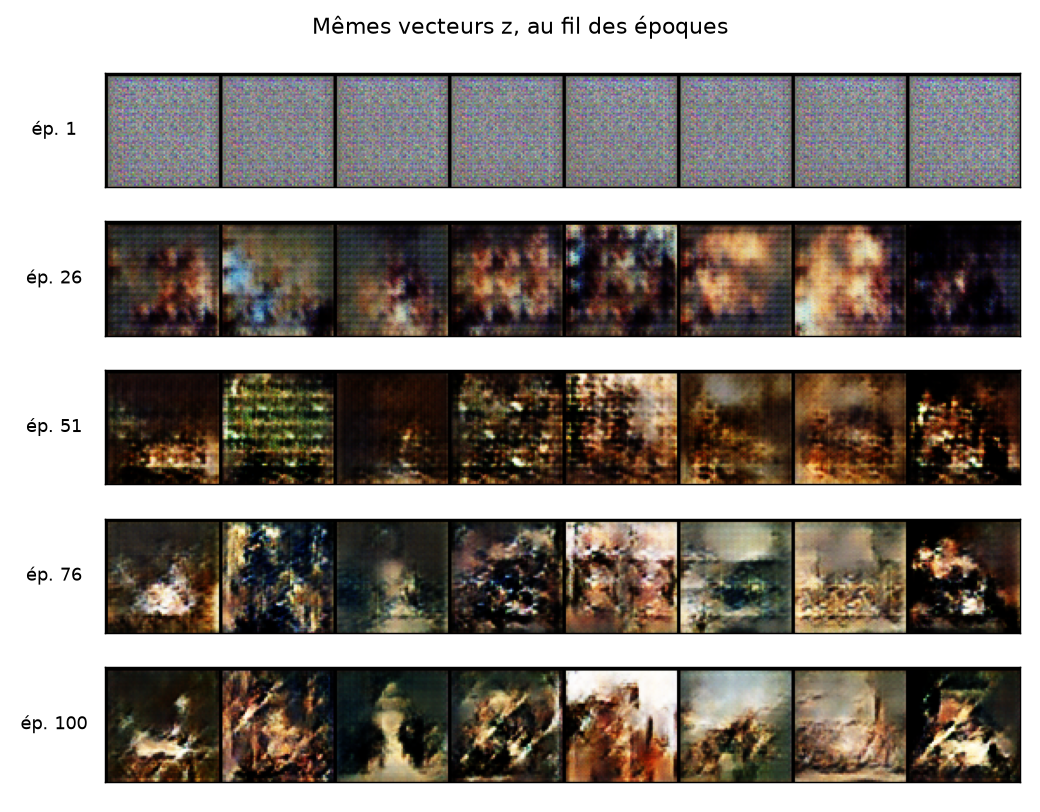

samples


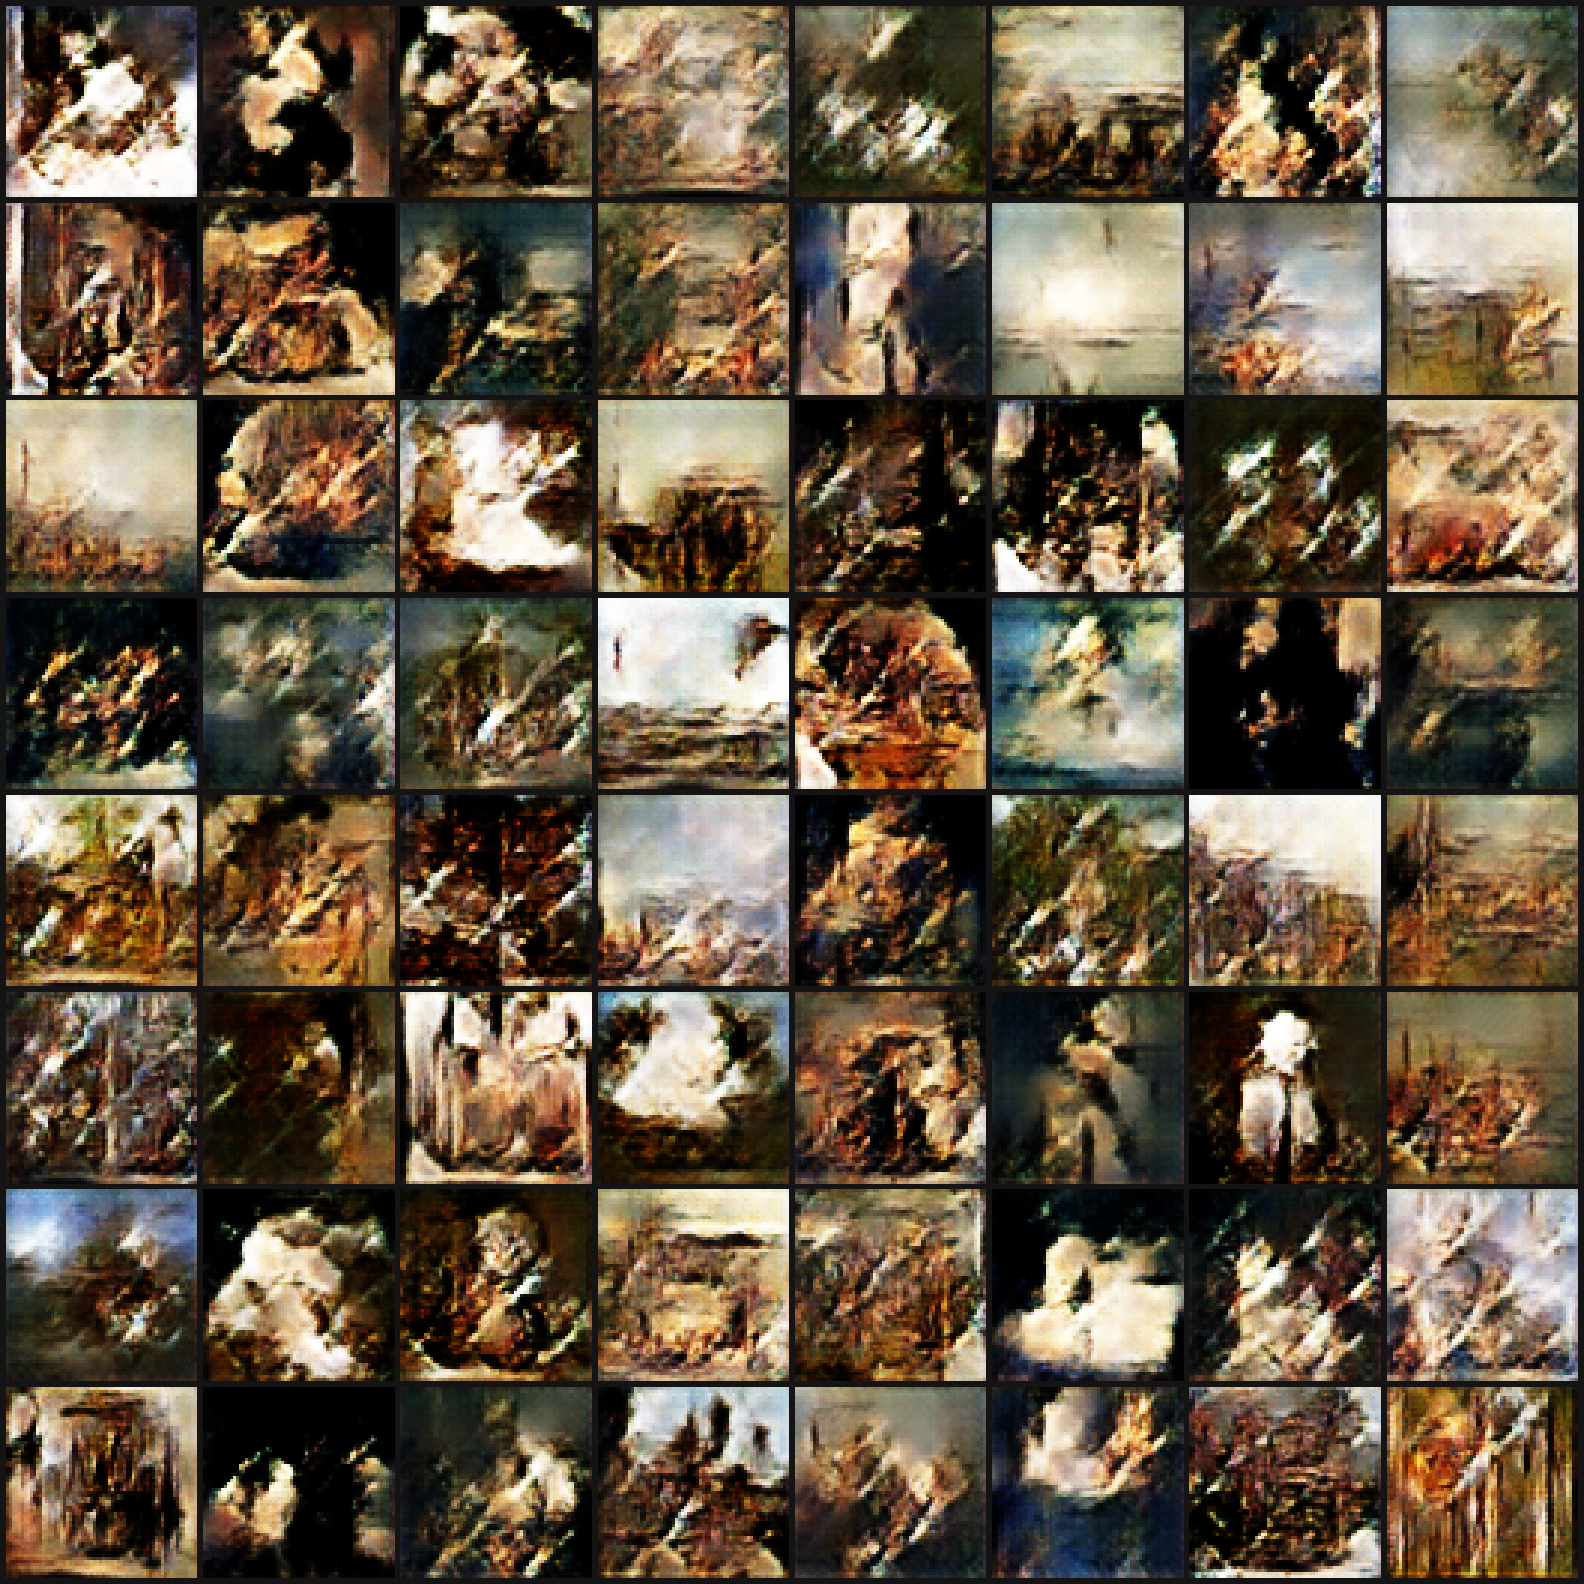

nearest_neighbors


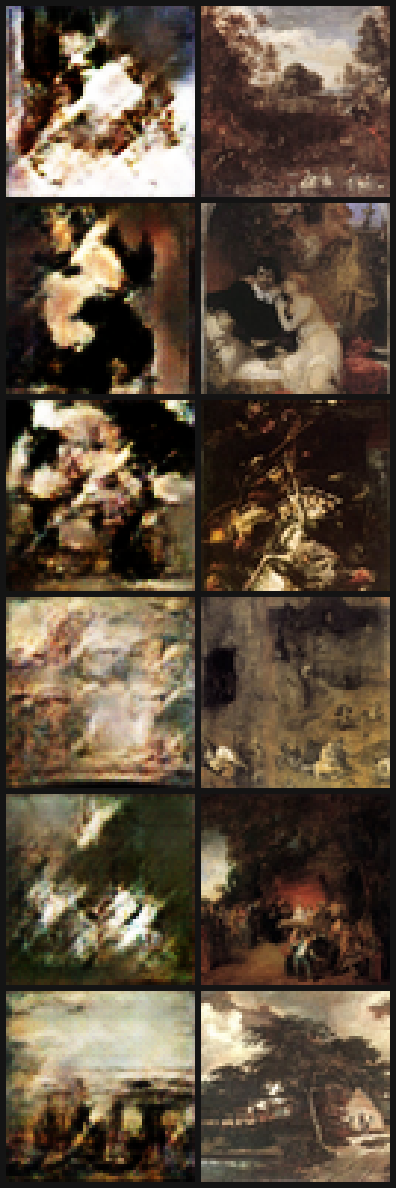

In [10]:
for name, width in (("losses", 900), ("progression", 760), ("samples", 640), ("nearest_neighbors", 260)):
    print(name)
    display(Image(filename=str(REPORT / "figures" / f"{name}.png"), width=width))

## 8. Analyse des résultats (Q8)

### Comparaison v0 → modèle final, sur le même jeu d'évaluation

Pour comparer honnêtement, les deux générateurs sont évalués contre **les mêmes 657 peintures
d'évaluation**, avec le même nombre d'images générées (`python -m ganisme.compare`, résultats dans
`reports/training/comparison.json`). Les valeurs de la v0 ci-dessous diffèrent donc de celles de son
évaluation d'origine (296 images) : un FID ne se compare qu'à protocole identique.

| | FID ↓ | KID ↓ |
| --- | --- | --- |
| Référence : vraies peintures vs vraies peintures | 62 | 0,000 |
| Baseline v0 (2 857 images, 660 itérations) | 335 | 0,305 |
| **Modèle final (6 105 images, 4 700 itérations)** | **211** | **0,150** |

- Le FID baisse de **37 %** et le KID est **divisé par deux** : l'hypothèse « plus de données et plus
  d'itérations, même architecture » est **confirmée**.
- L'écart avec la référence (211 contre 62) reste grand : les images générées restent faciles à
  distinguer de vraies peintures.

### Ce que montrent les images

- **Le damier de la v0 a disparu** et le **mode collapse aussi** : les 64 images de la grille sont toutes
  différentes.
- On reconnaît une **matière picturale** : tons ocre, bruns et dorés, clairs-obscurs, ciels pâles au-dessus
  de sols sombres, masses qui évoquent des bouquets, des paysages ou des intérieurs.
- **Aucun objet ni personnage n'est identifiable** : les images restent impressionnistes, presque abstraites.
- **Nouvel artefact** : des traînées claires en diagonale reviennent sur beaucoup d'images. C'est une forme
  plus légère de répétition d'un motif, à surveiller.
- **Pas de recopie** : les plus proches voisins dans le jeu d'entraînement sont des peintures nettement
  différentes des images générées.

### Les courbes

Les pertes se stabilisent après environ 1 000 itérations et oscillent ensuite, comme attendu pour un GAN.
Le discriminateur garde l'avantage tout au long de l'entraînement (D(x) ≈ 0,8, D(G(z)) ≈ 0,2), sans
toutefois écraser le générateur : il ne s'est pas effondré.

### Pistes d'amélioration (une hypothèse à la fois)

1. **Adoucir les étiquettes du discriminateur** (0,9 au lieu de 1) pour réduire son avantage.
2. **WGAN-GP**, plus stable, si les traînées répétitives persistent.
3. **Passer en 128×128** (les images sont archivées en 256×256, sans retéléchargement) pour plus de détails.
4. **GAN conditionnel** pour choisir le genre généré (paysage, portrait, nature morte…).